<a href="https://colab.research.google.com/github/whoCodesEverything/epias-anomaly-detection/blob/main/Epia%C5%9FApiElektrikT%C3%BCketim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install "eptr2[allextras]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 996.7/996.7 kB 18.7 MB/s  0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0
  Attempting uninstall: opentelemetry-api
    Found existing installation: opentelemetry-api 1.42.1
    Uninstalling opentelemetry-api-1.42.1:
      Successfully uninstalled opentelemetry-api-1.42.1
  Attempting uninstall: authlib
    Found existing installation: Authlib 1.9.3
    Uninstalling Authlib-1.9.3:
      Successfully uninstalled Authlib-1.9.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25/25 [fastmcp]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
opentelemetry-semantic-conventions 0.63b1 requires open

In [24]:
from google.colab import userdata
from eptr2 import EPTR2
import pandas as pd
from datetime import datetime, timedelta

# Colab Secrets üzerinden kullanıcı adı ve şifreyi güvenle çekme
username = userdata.get('EPTR2_USERNAME')
password = userdata.get('EPTR2_PASSWORD')

# EPİAŞ istemcisini başlatma
eptr = EPTR2(username=username, password=password, recycle_tgt=True)

# Zaman aralığı belirleme (Son 14 gün)
end_date = datetime.now()
start_date = end_date - timedelta(days=14)

start_str = start_date.strftime('%Y-%m-%d')
end_str = end_date.strftime('%Y-%m-%d')

print(f"Veri çekilen aralık: {start_str} ile {end_str}")

# 1. Gerçek Zamanlı Tüketim Verisini Çekme (Doğru anahtar: 'rt-cons')
df_consumption = eptr.call("rt-cons", start_date=start_str, end_date=end_str)
print("Tüketim verisi satır sayısı:", len(df_consumption))

# 2. Yenilenebilir Üretim Verisini Çekme (Doğru anahtar: 'rt-gen')
try:
    df_generation = eptr.call("rt-gen", start_date=start_str, end_date=end_str)
    print("Yenilenebilir üretim verisi satır sayısı:", len(df_generation))
except Exception as e:
    print("Üretim verisi çekilirken uyarı:", e)
    df_generation = pd.DataFrame()

display(df_consumption.head(3))

Dotenv file not found at .env.


Veri çekilen aralık: 2026-11-04 ile 2026-11-18
Tüketim verisi satır sayısı: 358
Yenilenebilir üretim verisi satır sayısı: 358


,date,time,consumption
0,2026-11-04T00:00:00+03:00,00:00,35625.11
1,2026-11-04T01:00:00+03:00,01:00,33821.60
2,2026-11-04T02:00:00+03:00,02:00,32592.59


In [26]:
# 1. Colab interaktif tablo eklentisini etkinleştirme
%load_ext google.colab.data_table

# (İsteğe bağlı) Sadece önemli sütunları seçip daha sade bir görünüm elde etme
# Not: Sütun isimleri EPİAŞ'tan gelen verilere göre 'date', 'consumption' veya benzeri olabilir.
# DataFrame içindeki sütunları görmek için önce df_consumption.columns yazdırabiliriz.
print("Mevcut sütunlar:", df_consumption.columns.tolist())

# Eğer sütun adları farklıysa buradaki isimleri tablodaki gerçek adlarla güncelleyebilirsiniz
# Örnek sadeleştirme ve sıralama:
clean_df = df_consumption[['date', 'consumption']].copy()
clean_df['consumption'] = pd.to_numeric(clean_df['consumption'], errors='coerce')

# İnteraktif tabloyu göster (Artık altında sayfalama tuşları, arama çubuğu ve sıralama olacaktır)
display(clean_df)

The google.colab.data_table extension is already loaded. To reload it, use:
  %reload_ext google.colab.data_table
Mevcut sütunlar: ['date', 'time', 'consumption']


,date,consumption
0,2026-11-04T00:00:00+03:00,35625.11
1,2026-11-04T01:00:00+03:00,33821.60
2,2026-11-04T02:00:00+03:00,32592.59
3,2026-11-04T03:00:00+03:00,31907.49
4,2026-11-04T04:00:00+03:00,31676.09
...,...,...
353,2026-11-18T17:00:00+03:00,47474.96
354,2026-11-18T18:00:00+03:00,46342.36
355,2026-11-18T19:00:00+03:00,43968.18
356,2026-11-18T20:00:00+03:00,42101.46


In [27]:
import numpy as np
import pandas as pd

# 1. Kayan Pencere (Rolling Window) ile Hareketli Ortalama ve Standart Sapma Hesaplama
window_size = 24  # 24 saatlik pencere
threshold_multiplier = 2.0 # Anomali eşik çarpanı

clean_df['rolling_mean'] = clean_df['consumption'].rolling(window=window_size, min_periods=1).mean()
clean_df['rolling_std'] = clean_df['consumption'].rolling(window=window_size, min_periods=1).std().fillna(1)

# Üst sınır ve anomali tespiti
clean_df['upper_bound'] = clean_df['rolling_mean'] + (threshold_multiplier * clean_df['rolling_std'])
clean_df['is_anomaly'] = clean_df['consumption'] > clean_df['upper_bound']

# Anomalileri filtreleme ve özet bilgi
anomalies = clean_df[clean_df['is_anomaly']]
print(f"Toplam tespit edilen ani yük sıçraması (anomali) sayısı: {len(anomalies)}")

Toplam tespit edilen ani yük sıçraması (anomali) sayısı: 6


In [28]:
# 2. Sonuçları CSV olarak kaydetme
clean_df.to_csv("epias_temiz_anomaliler.csv", index=False, encoding='utf-8-sig')
print("Sonuçlar 'epias_temiz_anomaliler.csv' dosyasına kaydedildi.")

Sonuçlar 'epias_temiz_anomaliler.csv' dosyasına kaydedildi.


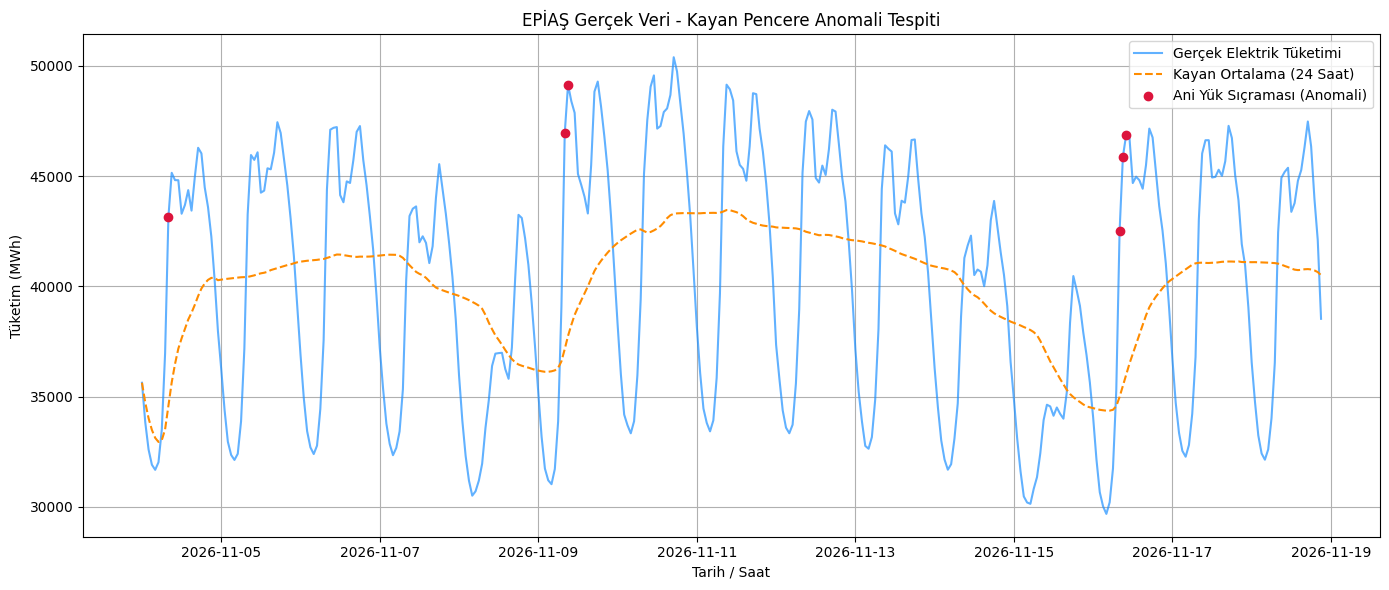

Grafik 'epias_anomali_grafigi.png' olarak kaydedildi.


In [29]:
import matplotlib.pyplot as plt

# 3. Grafik Üzerinde Görselleştirme
plt.figure(figsize=(14, 6))
plt.plot(pd.to_datetime(clean_df['date']), clean_df['consumption'], label='Gerçek Elektrik Tüketimi', color='dodgerblue', alpha=0.7)
plt.plot(pd.to_datetime(clean_df['date']), clean_df['rolling_mean'], label='Kayan Ortalama (24 Saat)', color='darkorange', linestyle='--')

if not anomalies.empty:
    plt.scatter(
        pd.to_datetime(anomalies['date']),
        anomalies['consumption'],
        color='crimson',
        label='Ani Yük Sıçraması (Anomali)',
        zorder=5
    )

plt.title('EPİAŞ Gerçek Veri - Kayan Pencere Anomali Tespiti')
plt.xlabel('Tarih / Saat')
plt.ylabel('Tüketim (MWh)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('epias_anomali_grafigi.png')
plt.show()
print("Grafik 'epias_anomali_grafigi.png' olarak kaydedildi.")

Toplam tespit edilen ani yük sıçraması (anomali) sayısı: 6
Sonuçlar başarıyla 'epias_temiz_anomaliler.csv' dosyasına kaydedildi.


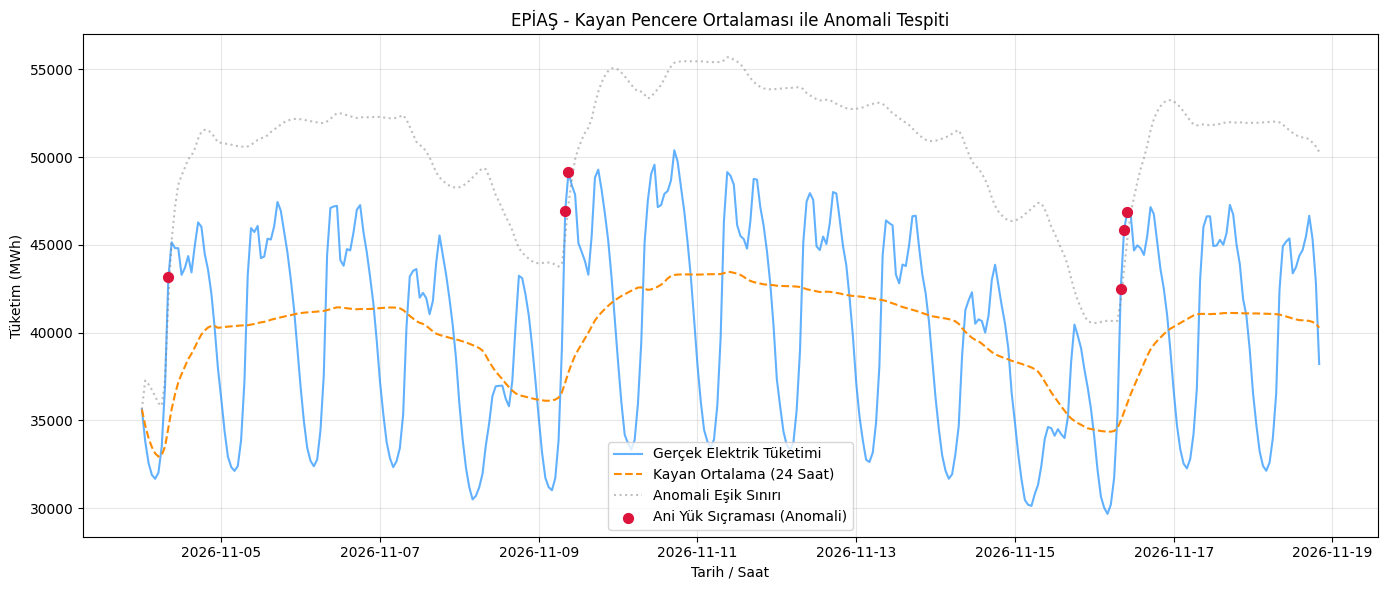

Grafik başarıyla 'epias_anomali_grafigi.png' olarak kaydedildi.


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Örnek olarak 'clean_df' içinde 'date' ve 'consumption' sütunlarınızın olduğunu varsayuyoruz.
# 1. Kayan Pencere (Rolling Window) ile Anomali Tespiti
window_size = 24            # 24 saatlik pencere
threshold_multiplier = 2.0  # Anomali eşik çarpanı

# Hareketli ortalama ve standart sapma hesaplama
clean_df['rolling_mean'] = clean_df['consumption'].rolling(window=window_size, min_periods=1).mean()
clean_df['rolling_std'] = clean_df['consumption'].rolling(window=window_size, min_periods=1).std().fillna(1)

# Üst sınırın belirlenmesi ve anomali tespiti (ani yük sıçramaları)
clean_df['upper_bound'] = clean_df['rolling_mean'] + (threshold_multiplier * clean_df['rolling_std'])
clean_df['is_anomaly'] = clean_df['consumption'] > clean_df['upper_bound']

# Anomalileri filtreleme
anomalies = clean_df[clean_df['is_anomaly']]
print(f"Toplam tespit edilen ani yük sıçraması (anomali) sayısı: {len(anomalies)}")


# 2. Sonuçları CSV Olarak Kaydetme
output_csv = "epias_temiz_anomaliler.csv"
clean_df.to_csv(output_csv, index=False, encoding='utf-8-sig')
print(f"Sonuçlar başarıyla '{output_csv}' dosyasına kaydedildi.")


# 3. Grafik Üzerinde Görselleştirme
plt.figure(figsize=(14, 6))
plt.plot(pd.to_datetime(clean_df['date']), clean_df['consumption'], label='Gerçek Elektrik Tüketimi', color='dodgerblue', alpha=0.7)
plt.plot(pd.to_datetime(clean_df['date']), clean_df['rolling_mean'], label='Kayan Ortalama (24 Saat)', color='darkorange', linestyle='--')

# Üst sınır bandını opsiyonel olarak çizdirme (isteğe bağlı netlik için)
plt.plot(pd.to_datetime(clean_df['date']), clean_df['upper_bound'], label='Anomali Eşik Sınırı', color='gray', linestyle=':', alpha=0.5)

if not anomalies.empty:
    plt.scatter(
        pd.to_datetime(anomalies['date']),
        anomalies['consumption'],
        color='crimson',
        label='Ani Yük Sıçraması (Anomali)',
        zorder=5,
        s=50
    )

plt.title('EPİAŞ - Kayan Pencere Ortalaması ile Anomali Tespiti')
plt.xlabel('Tarih / Saat')
plt.ylabel('Tüketim (MWh)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

output_image = 'epias_anomali_grafigi.png'
plt.savefig(output_image)
plt.show()
print(f"Grafik başarıyla '{output_image}' olarak kaydedildi.")